# **Mapping short-let pressure in Bristol: A neighbourhood analysis of Airbnb listings**

# EDA objectives 

**Core question:** 

Where in Bristol are professional short-let operators concentrated, and how do their listings differ from those of casual hosts?

**Our definitions:**

- Operator listing: the host has 3 or more listings in this dataset. The sensitivity check uses 5 or more.
- Casual listing: the host has 1 or 2 listings.
- Concentration: the share of an area’s listings that are operator listings.

Main analysis subset: active listings (2,561). The robustness check uses current-scrape listings only (2,227).

**The questions we are exploring:**

H1: concentration varies by area.

The operator share is not the same across the 34 neighbourhoods.

- Null: any differences are no bigger than chance.
- Test: chi-square on area against operator status. Areas with very few listings may need combining.
- Charts: V2 (bar) and V3 (map).

H2: operator listings behave differently.

Compared with casual hosts, operator listings have higher annual availability and different minimum-stay requirements, as full-time commercial lettings would.

- Null: no difference.
- Test: Mann-Whitney on availability_365 and minimum_nights, reported with an effect size. Rank-based, because both are heavily skewed.
- Charts: V4 and V5.

H3: operator listings are rated differently.

Review scores differ between operator and casual listings. An early check suggested operators score lower.
- Null: no difference.
- Test: Mann-Whitney on review_scores_rating, with an effect size.
- Caveat: this uses only the 2,644 reviewed listings, so it describes reviewed listings, not all of them.
- Chart: V6.

**Process steps**

**Inputs**

# Change working directory

In [1]:
import os
current_dir = os.getcwd()
current_dir

'c:\\Users\\chheb\\OneDrive\\Documents\\Programming\\Mapping_Short_Let-Pressure_in_Bristol\\jupyter_notebooks'

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


In [3]:
current_dir = os.getcwd()
current_dir

'c:\\Users\\chheb\\OneDrive\\Documents\\Programming\\Mapping_Short_Let-Pressure_in_Bristol'

# Import transformed data

In [4]:
import json
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

In [5]:
df = pd.read_csv("data/processed/listings_clean.csv", dtype={"id": str},
                 parse_dates=["first_review", "last_review"])
print(df.shape) 

(2932, 51)


# Exploring the data


## Neighbourhood table ##

**Purpose.** Hypothesis H1 and the map and bar charts need one row per neighbourhood. This table summarises the active listings (2,561) for each of the 34 areas, using the main-analysis subset decided in the transformation stage.

**Columns.** Listing counts, operator share at 3+ and 5+ listings, entire-home share, and median availability, minimum stay and rating.

**Checks.** 34 areas, 2,561 listings in total, and an overall operator share that matches the active-only figure from step 2 (about 42%).

**Caution.** [N] areas have fewer than 30 listings, so their shares are unstable. They are flagged in `small_area` and shown with their counts in the charts. The 30-listing cut-off is a judgement.

In [6]:
active = df[df["is_active"]]            
g = active.groupby("neighbourhood_cleansed")

area = pd.DataFrame({
    "listings": g.size(),
    "operator_listings": g["is_operator"].sum(),
    "operator_share": g["is_operator"].mean(),
    "operator_share_5": g["is_operator_5"].mean(),
    "entire_home_share": g["is_entire_home"].mean(),
    "median_availability_365": g["availability_365"].median(),
    "median_min_nights": g["minimum_nights"].median(),
    "median_rating": g["review_scores_rating"].median(),
})
area["all_listings"] = df.groupby("neighbourhood_cleansed").size()    
area["small_area"] = area["listings"] < 30                            
area = area.round(3)




In [7]:
print(len(area))                                                       
print(area["listings"].sum())                                          
print((area["operator_listings"].sum() / area["listings"].sum()).round(3))   
print("Small areas:", area["small_area"].sum())                        

area.sort_values("operator_share", ascending=False).head(10)

34
2561
0.42
Small areas: 5


,listings,operator_listings,operator_share,operator_share_5,entire_home_share,median_availability_365,median_min_nights,median_rating,all_listings,small_area
neighbourhood_cleansed,,,,,,,,,,
Central,231,146,0.632,0.515,0.853,281.0,1.0,4.720,254,False
Clifton Down,166,102,0.614,0.476,0.886,264.5,2.0,4.835,176,False
Lawrence Hill,119,70,0.588,0.513,0.807,260.0,1.0,4.750,142,False
Hotwells & Harbourside,104,59,0.567,0.510,0.913,294.0,2.0,4.750,111,False
Horfield,76,42,0.553,0.382,0.487,198.5,2.0,4.840,83,False
Cotham,112,54,0.482,0.357,0.741,209.5,2.0,4.830,130,False
Clifton,173,78,0.451,0.364,0.931,246.0,2.0,4.810,205,False
Southville,133,58,0.436,0.353,0.692,155.0,2.0,4.880,153,False
Ashley,273,118,0.432,0.311,0.700,160.0,2.0,4.870,314,False


This table shows us three important things for our analysis straight away:

- The spread is large. Operator share is 63.2% in Central and 61.4% in Clifton Down, against a Bristol average of about 42%. This already supports the idea behind H1, though it needs confirming through the chi-square test.
- Stockwood is an example of how small-area could be misleading. It sits in the top ten at 42.9%, but that is 6 of 14 listings. One more or fewer operator listing moves it by about 7 points. This is why V2 shows the count for each bar.
- Operators aren’t only entire homes. Horfield has a 55.3% operator share but only 48.7% entire homes, against 85% to 93% in the other top areas. A different kind of operator activity may be happening there.

## V0: Distributions ##

We need to explore whether the main listing measures evenly spread, or dominated by a few extreme values. The answer is crucial for deciding which summaries and statistical tests are appropriate for the rest of the analysis.

I plotted a histogram for each of four measures across the 2,561 active listings: 
- `price` 
- `minimum_nights`
- `availability_365`
- `calculated_host_listings_count` 

On each, the mean (dashed line) and median (solid line) are marked, and a table reports the mean, median and skewness.

I choose these four measures because they are the ones the hypotheses and the model will rely on. Price and availability describe how a listing is run, minimum stay is tested in H2, and the host listing count defines an operator.


                                  mean  median  skewness
price                           157.22   130.0      5.95
minimum_nights                    3.54     2.0     14.75
availability_365                202.20   239.0     -0.25
calculated_host_listings_count   13.54     2.0      3.10


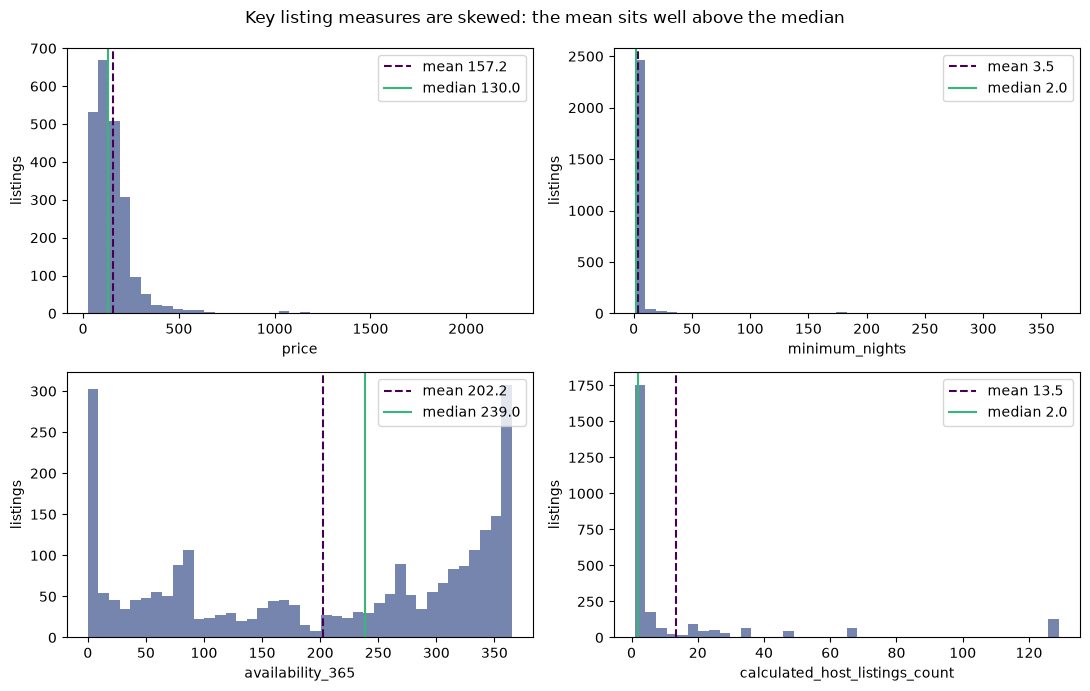

In [8]:
skew_cols = ["price", "minimum_nights", "availability_365", "calculated_host_listings_count"]
print(pd.DataFrame({"mean": active[skew_cols].mean(),
                    "median": active[skew_cols].median(),
                    "skewness": active[skew_cols].skew()}).round(2))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), skew_cols):
    data = active[col].dropna()
    ax.hist(data, bins=40, color="#3b528b", alpha=0.7)
    ax.axvline(data.mean(), color="#440154", linestyle="--", label=f"mean {data.mean():.1f}")
    ax.axvline(data.median(), color="#35b779", linestyle="-", label=f"median {data.median():.1f}")
    ax.set_xlabel(col); ax.set_ylabel("listings"); ax.legend()
fig.suptitle("Key listing measures are skewed: the mean sits well above the median")
plt.tight_layout()
plt.show()


- Three of the four measures are strongly right-skewed (skewness well above 1). A small number of extreme values pull the mean above the median: a few very expensive properties, a few listings that require a month or more (up to 365 nights), and a few hosts with dozens of listings, the largest with 129.
- `availability_365` is different. Its skewness is close to zero and its mean sits slightly below its median, so it is not dominated by extreme values. few listings sit at exactly 365 days (2.6% to 3.3%) but many sit close to it, so the right-hand cluster is “most of the year”, not “fully open”. Without a threshold calculation, don’t put a number on “close to it” (see V4 for more detail).

**What this means for the analysis**

- For skewed measures the mean is a poor summary of a typical listing, so we report medians when describing one.
- The comparisons in H2 and H3 use rank-based tests (Mann-Whitney), which compare the order of values and are not distorted by a few extremes. A t-test, which compares means, would be. For availability the case is weaker, because it is not skewed. A rank-based test is still appropriate because it does not assume the values follow a bell-shaped curve, and [CONFIRM from the histogram that availability is not bell-shaped].
- Log-transforming was considered for the skewed measures. It does not suit minimum stay, which is mostly one to three nights. Where a chart needs to show a long tail (for example price), a log axis is used and labelled.

It is important to note that skew shows that extreme values exist, not that they are errors. The extremes checked in the outlier step of our ETL process were genuine listings, so they stay in the data.

## V1: What is the market's composition? ##

Our next task is getting a clearer picture of what is the market made of. In particualr, we want to know whether operator and casual listings differ in the type of property they offer?

I used a a stacked bar chart to compare the room-type mix of operator listings (hosts with 3 or more listings, n=1,075) and casual listings (1 to 2 listings, n=1,486) among active listings. This means the two groups are comparable despite thier different sizes.

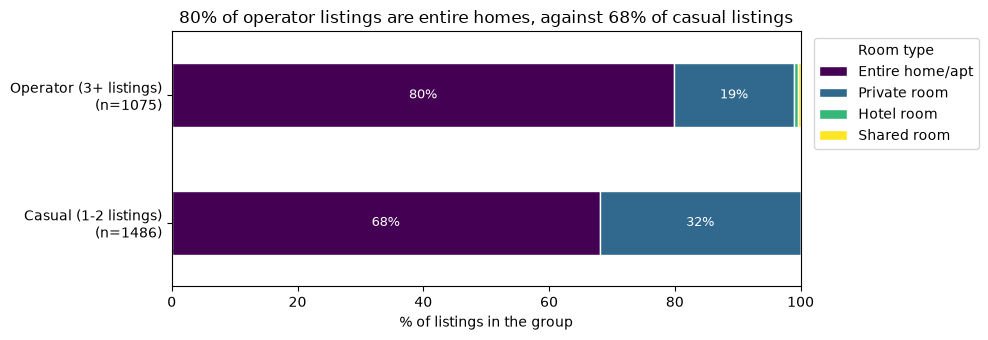

In [9]:
labels = {True: "Operator (3+ listings)", False: "Casual (1-2 listings)"}
group = active["is_operator"].map(labels)
order = ["Entire home/apt", "Private room", "Hotel room", "Shared room"]

comp = pd.crosstab(group, active["room_type"], normalize="index")[order] * 100
n = group.value_counts()

ax = comp.plot(kind="barh", stacked=True, figsize=(10, 3.5), colormap="viridis", edgecolor="white")
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0f}%" if v >= 4 else "" for v in c.datavalues],
                 label_type="center", color="white", fontsize=9)

ax.set_yticklabels([f"{g}\n(n={n[g]})" for g in comp.index])
ax.set_xlabel("% of listings in the group")
ax.set_ylabel("")
op_home = comp.loc[labels[True], "Entire home/apt"]
cas_home = comp.loc[labels[False], "Entire home/apt"]
ax.set_title(f"{op_home:.0f}% of operator listings are entire homes, against {cas_home:.0f}% of casual listings")
ax.legend(title="Room type", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

  

In [10]:
comp.round(1)  

room_type,Entire home/apt,Private room,Hotel room,Shared room
is_operator,,,,
Casual (1-2 listings),68.0,32.0,0.0,0.0
Operator (3+ listings),79.9,19.0,0.7,0.5


In [11]:
active.groupby("room_type")["is_operator"].agg(["size", "mean"]).round(3)

,size,mean
room_type,,
Entire home/apt,1870,0.459
Hotel room,7,1.000
Private room,679,0.300
Shared room,5,1.000


- Entire homes make up the majority in both groups. But this definately more the case for operators, with entire homes making up 80% of thier listings (compraed to 68% of casual listings).
- Private rooms make up 19% of operator listings and 32% of casual listings.
- Hotel and shared rooms are under 1% of either group.

**What this means for Bristol City Council.** 

Operator activity is concentrated in entire homes, the property type most likely to be taken out of long-term housing. We can see that operators hold about 46 of all active entire-home listings. However,  the data cannot show whether those homes were previously rented to residents.

**Linitations:** 

The chart shows the mix within each group, not the share of each room type that operators hold. "Casual" includes hosts with two listings, and the 3-listing threshold is a judgement call. This is a description, not a test. In reality, it does not show that the difference is more than chance.

## V2: Are operators concentrated in certain areas?

An important part of our understanding of the data is seeing if professional operators are concentrated in certain areas? This is the basis of H1.

I calculated the share of active listings run by operators (hosts with 3 or more listings) in each of the 34 neighbourhoods, and ranked them. Bar labels show the number of active listings behind each share, and areas with fewer than 30 listings are shaded grey.

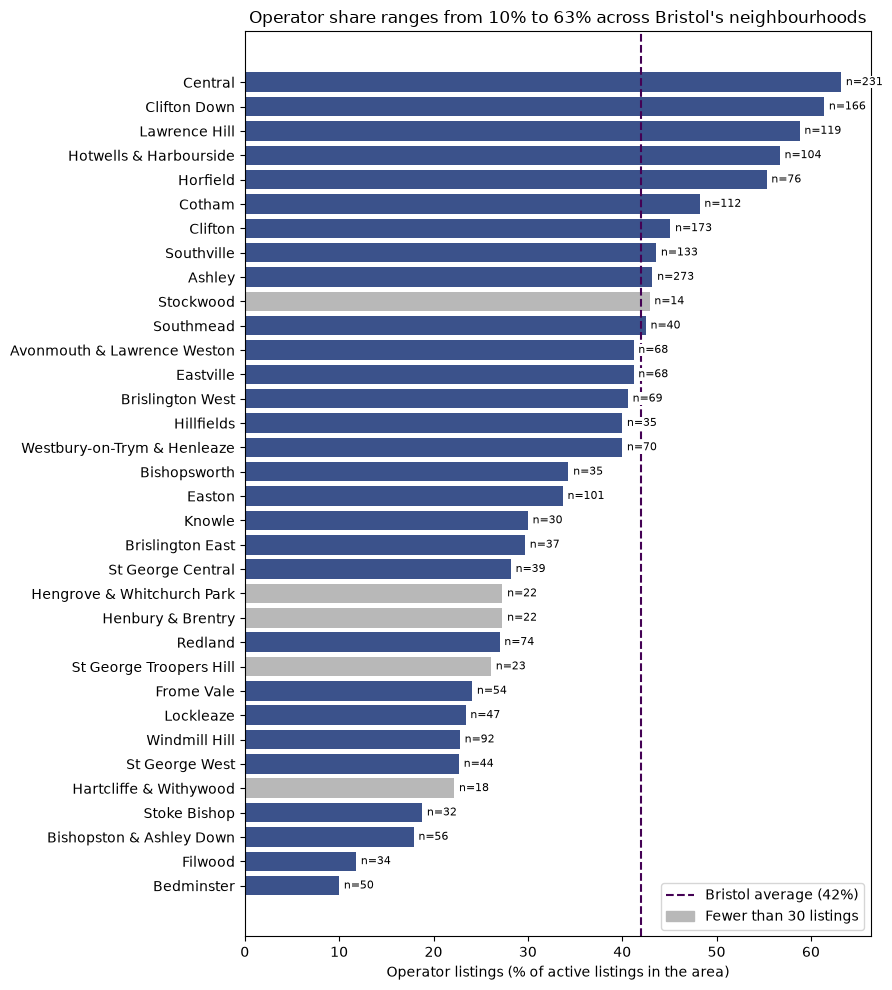

In [12]:
from matplotlib.patches import Patch

plot = area.reset_index().sort_values("operator_share")
overall = active["is_operator"].mean() * 100
lo, hi = plot["operator_share"].min() * 100, plot["operator_share"].max() * 100

fig, ax = plt.subplots(figsize=(9, 10))
colors = np.where(plot["small_area"], "#b8b8b8", "#3b528b")        # grey = fewer than 30 listings
ax.barh(plot["neighbourhood_cleansed"], plot["operator_share"] * 100, color=colors)
ax.axvline(overall, color="#440154", linestyle="--", label=f"Bristol average ({overall:.0f}%)")

for y, (share, n) in enumerate(zip(plot["operator_share"], plot["listings"])):
    ax.text(share * 100 + 0.5, y, f"n={n}", va="center", fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5))   # keeps labels readable over the line

ax.set_xlabel("Operator listings (% of active listings in the area)")
ax.set_title(f"Operator share ranges from {lo:.0f}% to {hi:.0f}% across Bristol's neighbourhoods")

handles, _ = ax.get_legend_handles_labels()
handles.append(Patch(color="#b8b8b8", label="Fewer than 30 listings"))
ax.legend(handles=handles)

plt.tight_layout()
plt.show()


- Operator share varies widely, from 10% in Bedminster to 63% in Central, against a Bristol average of 42%.
- Four areas (Central, Clifton Down, Lawrence Hill, Hotwells & Harbourside) have shares above 55%. Together they hold 24% of active listings but 35% of operator listings.
- Most areas are below the Bristol average. The average is pulled up by a small number of large, high-share areas.

**What this means for Bristol City Council.** 

Operator activity is not spread evenly. A small number of areas account for a disproportionate share of it, so any attention to professional short-lets would reach more of it by starting there.

**Limitations:**

- Five areas have fewer than 30 listings, and several more have 30 to 40, so their shares are unstable. The 30-listing cut-off is a judgement.
- The chart shows the size of the differences, not whether they are more than chance.
- We can show where operator listings are, but not whether they are a direct cause of housing pressure.

# V3: Can we show that concentration on a map?

To explore H1, we can show geographically the cluser of operator activity in particular places. 

Coloured each of the 34 neighbourhoods by its operator share (the percentage of active listings run by hosts with 3 or more listings), using the council boundary file. Hovering over an area shows its listing count and flags areas with fewer than 30 listings.

In [13]:
import shutil
Path("data/processed").mkdir(parents=True, exist_ok=True)
shutil.copy("data/raw/neighbourhoods.geojson", "data/processed/neighbourhoods.geojson")

'data/processed/neighbourhoods.geojson'

In [14]:
with open("data/processed/neighbourhoods.geojson", encoding="utf-8") as f:
    geo = json.load(f)

map_df = area.reset_index()
map_df["operator_pct"] = (map_df["operator_share"] * 100).round(1)

fig = px.choropleth(
    map_df,
    geojson=geo,
    locations="neighbourhood_cleansed",
    featureidkey="properties.neighbourhood",
    color="operator_pct",
    color_continuous_scale="Viridis",
    hover_name="neighbourhood_cleansed",
    hover_data={"neighbourhood_cleansed": False, "operator_pct": ":.1f",
                "listings": True, "small_area": True},
    labels={"operator_pct": "Operator share (%)", "listings": "Active listings",
            "small_area": "Fewer than 30 listings"},
)
fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(
    title="Operators are clearly concentrated in the centre of the city",
    margin=dict(l=0, r=0, t=60, b=0),
    height=600,
)
fig.show()

**What we found**
- Operator share is highest in the central part of the city and neighbouring areas, including Central (63%) and Clifton Downshares (61%).
- Shares fall towards the outer areas, and are lowest in the south of the city, particuarly in Bedminster (10%) and Filwood (12%).
- High-share areas sit next to each other, so the pattern is geographic and not scattered.

**What this means for the Bristol City Council** 

Operator activity clusters in a connected central area. A response aimed at professional short-lets could be targeted geographically, not citywide.

**Limitations**

- The map gives every area the same visual weight whatever its size or number of listings, so large areas with few listings can look more important than they are. It should be read alongside V2, which shows the counts.
- Areas with few listings (shaded grey in V2) are coloured like any other, and their shares are unstable.
- Again, we can only describe where operator listings are, not whether they affect housing.

# V4: Is there a difference in availiability between operators and casuals?

We can now start to test H2 -  that operator and casual listings differ in terms of availiability.

stat="percent" with common_norm=False scales each group to 100% on its own. The groups have different sizes (1,075 against 1,486), so raw counts would make them hard to compare. bins=37 gives bars about 10 days wide.

The dashed lines mark each group’s median, and the title is built from the data so it states the finding.

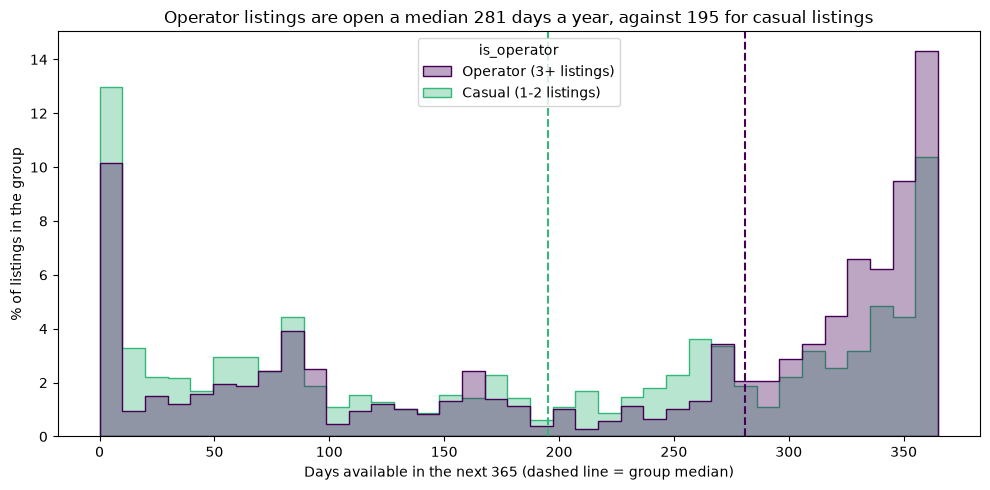

In [15]:
labels = {True: "Operator (3+ listings)", False: "Casual (1-2 listings)"}
group = active["is_operator"].map(labels)
palette = {labels[True]: "#440154", labels[False]: "#35b779"}

active.groupby(group)["availability_365"].describe()[["count", "25%", "50%", "75%"]]

med_op = active.loc[active["is_operator"], "availability_365"].median()
med_cas = active.loc[~active["is_operator"], "availability_365"].median()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=active, x="availability_365", hue=group, bins=37, stat="percent",
             common_norm=False, element="step", alpha=0.35, palette=palette, ax=ax)
for lab, color in palette.items():
    ax.axvline(active.loc[group == lab, "availability_365"].median(), color=color, linestyle="--")

ax.set_xlabel("Days available in the next 365 (dashed line = group median)")
ax.set_ylabel("% of listings in the group")
ax.set_title(f"Operator listings are open a median {med_op:.0f} days a year, against {med_cas:.0f} for casual listings")
plt.tight_layout()
plt.show()

In [16]:
# 1. Exact shares at the extremes (fills the open V0 availability placeholder)
extremes = active.groupby(group)["availability_365"].agg(
    zero=lambda s: (s == 0).mean(),
    full_year=lambda s: (s == 365).mean(),
).round(3)
print(extremes)

# 2. Robustness: same medians on current-scrape listings only
current = active[~active["from_previous_scrape"]]
print(current.groupby(current["is_operator"].map(labels))["availability_365"].median())

                         zero  full_year
is_operator                             
Casual (1-2 listings)   0.093      0.026
Operator (3+ listings)  0.076      0.033
is_operator
Casual (1-2 listings)     241.0
Operator (3+ listings)    303.5
Name: availability_365, dtype: float64


We can see that both groups are U-shaped: a pile of listings with no availability (9.3% of casual and 7.6% of operator listings are at exactly 0 days) and a larger pile open for most of the year. Operator listings lean towards the second group (median 281 days against 195 for casual hosts).

**What it means for the council:** 

Operator listings are open more days a year, which fits H2's idea that they behave more like full-time commercial lettings. The gap is 86 days on all active listings and 62.5 days on current-scrape listings only (303.5 against 241), so the direction is stable but the size depends on the subset. 

**Limitations:** 

Availability is what a host leaves open, not how often the listing is booked. A calendar open most of the year can mean a full-time let or an unmanaged calendar. Listings with no availability may be dormant or blocked off, rather than rarely used. Previous-scrape listings may have stale calendars, which is why the current-scrape check is important.



# V5: Is there a difference in minimum stays between operators and casuals?

Looking at whether operator listings set different minimum-stay requirements from casual listings is the the second half of H2, alongside availability (V4).

The minimum nights is very skewed (median 2, mean 3.5, skewness 14.75), so a histogram would show one tall bar at 1-3 nights and an unreadable tail. Instead, listings are grouped into bands: 1, 2, 3, 4-6, 7-29 and 30+ nights. The 30-night edge matches the `is_short_stay` feature from the transformation stage. The chart shows the percentage of each host type's listings in each band, so the groups can be compared despite their different sizes (1,075 operator listings against 1,485 casual).

This uses active listings only. One active listing has no minimum-nights value and is excluded from the bands.

minimum_nights            1    2    3  4-6  7-29  30+
is_operator                                          
Casual (1-2 listings)   620  534  132  105    76   18
Operator (3+ listings)  513  360   68   50    71   13
minimum_nights             1     2    3  4-6  7-29  30+
is_operator                                            
Casual (1-2 listings)   41.8  36.0  8.9  7.1   5.1  1.2
Operator (3+ listings)  47.7  33.5  6.3  4.7   6.6  1.2


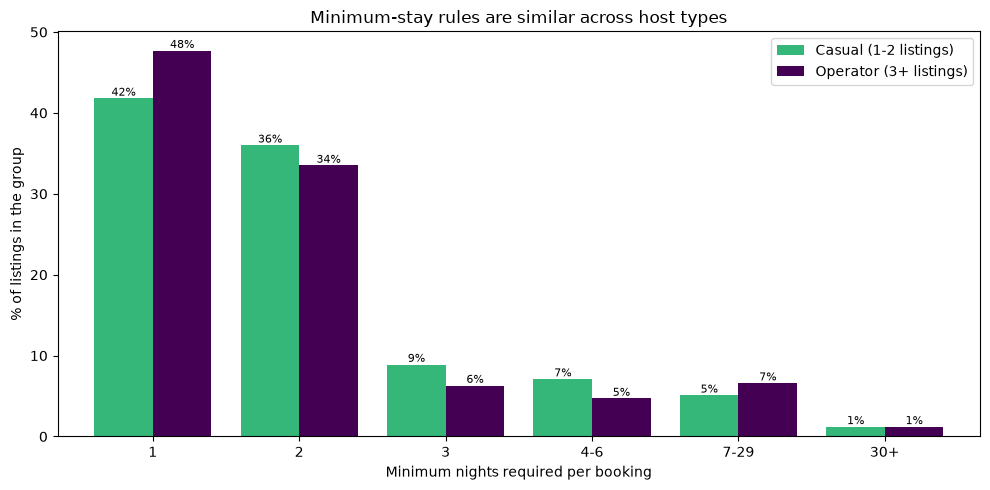

In [18]:
labels = {True: "Operator (3+ listings)", False: "Casual (1-2 listings)"}
group = active["is_operator"].map(labels)
palette = {labels[True]: "#440154", labels[False]: "#35b779"}

bands = pd.cut(active["minimum_nights"], bins=[0, 1, 2, 3, 6, 29, np.inf],
               labels=["1", "2", "3", "4-6", "7-29", "30+"])

counts = pd.crosstab(group, bands)                          # n per cell
share = (pd.crosstab(group, bands, normalize="index") * 100).round(1)
print(counts)
print(share)

short = share[["1", "2"]].sum(axis=1)                       # % requiring 1-2 nights

fig, ax = plt.subplots(figsize=(10, 5))
share.T.plot(kind="bar", ax=ax, color=[palette[c] for c in share.index], width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", fontsize=8)
ax.set_xlabel("Minimum nights required per booking")
ax.set_ylabel("% of listings in the group")
ax.set_title("Minimum-stay rules are similar across host types")
ax.tick_params(axis="x", rotation=0)
ax.legend(title=None)
plt.tight_layout()
plt.show()

The two host types are broadly similar when it comes to minimum nights. Both are concentrated at 1-2 nights (81% of operator listings, 78% of casual listings). The clearest difference is at 1 night: 48% of operator listings against 42% of casual.

**What it means for Bristol City Council:** 

Minimum stay barely separates the two groups. Operator listings are slightly more likely to accept single-night bookings, which is consistent with a commercial short-let model, but the difference is small. Unlike availability (V4), minimum stay is not a strong signal of professional operation.

**Limitations:** 

Minimum stay is a host setting that can change by season, and one listing has no value. The 30+ band holds only 31 listings in total (18 casual, 13 operator), so its percentages are unreliable. The band edges are a judgement call.

# V6: Are operator listings rated differently?

Another core question is whether operator listings rated differently from casual listings? 

Ratings are capped at 5 and bunched near the top, so the distribution is skewed to the left and a mean would be pulled down by a few poor ratings. The chart overlays the rating distribution for each host type as a percentage of that group, so the groups can be compared despite their different sizes. Dashed lines mark the group medians.

Active listings that have a rating (1,348 casual and 974 operator listings). Listings with no rating are excluded, not filled in, because there is nothing to compare. Before charting, I checked that the groups are comparable on coverage: 90.7% of casual and 90.6% of operator listings have a rating.

                         count     25%    50%  75%
is_operator                                       
Casual (1-2 listings)   1348.0  4.8000  4.920  5.0
Operator (3+ listings)   974.0  4.4725  4.745  4.9
is_operator
Casual (1-2 listings)     0.907
Operator (3+ listings)    0.906
Name: review_scores_rating, dtype: float64


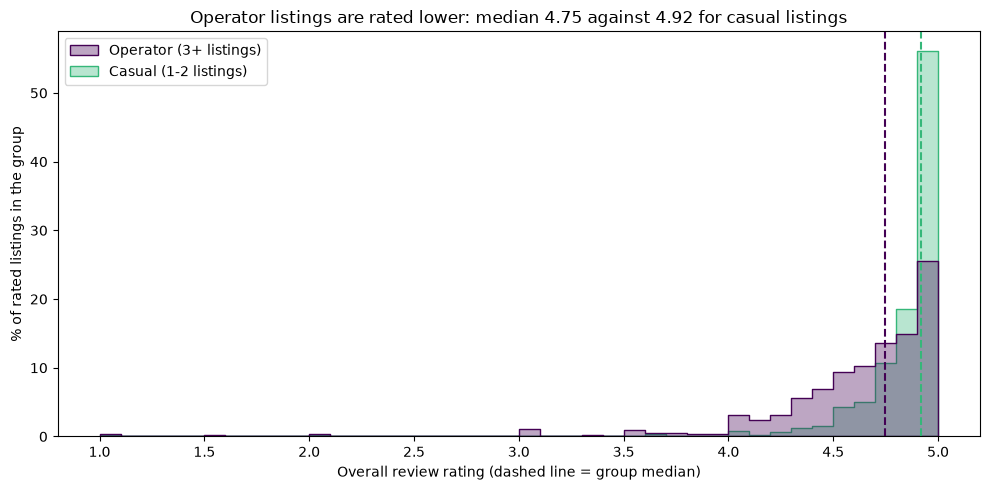

In [21]:
labels = {True: "Operator (3+ listings)", False: "Casual (1-2 listings)"}
group = active["is_operator"].map(labels)
palette = {labels[True]: "#440154", labels[False]: "#35b779"}

rated = active[active["review_scores_rating"].notna()]
rgroup = rated["is_operator"].map(labels)

# Figures behind the chart
print(rated.groupby(rgroup)["review_scores_rating"].describe()[["count", "25%", "50%", "75%"]])

# How many listings in each group have a rating at all?
print(active.groupby(group)["review_scores_rating"].apply(lambda s: s.notna().mean()).round(3))

med_op = rated.loc[rated["is_operator"], "review_scores_rating"].median()
med_cas = rated.loc[~rated["is_operator"], "review_scores_rating"].median()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=rated, x="review_scores_rating", hue=rgroup, binwidth=0.1, stat="percent",
             common_norm=False, element="step", alpha=0.35, palette=palette, ax=ax)
for lab, color in palette.items():
    ax.axvline(rated.loc[rgroup == lab, "review_scores_rating"].median(), color=color, linestyle="--")

ax.set_xlabel("Overall review rating (dashed line = group median)")
ax.set_ylabel("% of rated listings in the group")
ax.set_title(f"Operator listings are rated lower: median {med_op:.2f} against {med_cas:.2f} for casual listings")
ax.get_legend().set_title(None)
plt.tight_layout()
plt.show()

In [20]:
# Do the groups differ in how many reviews sit behind each rating?
print(rated.groupby(rgroup)["number_of_reviews"].median())

# Does the gap survive when we only look at well-reviewed listings?
for min_reviews in [1, 10]:        # 1 = all rated listings
    sub = rated[rated["number_of_reviews"] >= min_reviews]
    print(f"\nListings with {min_reviews}+ reviews")
    print(sub.groupby(sub["is_operator"].map(labels))["review_scores_rating"].agg(["count", "median"]))

is_operator
Casual (1-2 listings)     32.0
Operator (3+ listings)    22.0
Name: number_of_reviews, dtype: float64

Listings with 1+ reviews
                        count  median
is_operator                          
Casual (1-2 listings)    1348   4.920
Operator (3+ listings)    974   4.745

Listings with 10+ reviews
                        count  median
is_operator                          
Casual (1-2 listings)    1010    4.90
Operator (3+ listings)    666    4.73


We can clearly see that operators are rated lower. But I thought this may be a small-sample effect  I expected casual hosts to have fewer reviews, which would have inflated their ratings. The data shows the opposite: casual listings have a median of 32 reviews against 22 for operators. So the casual hosts’ high ratings aren’t a small-sample effect, and the gap is real in the data. The median is 4.92 for casual listings and 4.75 for operator listings. The operator upper quartile (4.90) sits below the casual median, so the whole operator distribution is shifted down, not just its tail. Operator listings spread further across the 4.0-4.8 range.

**What it means for the council:** Operator listings are rated lower than casual ones. This does not fit the idea that professional operators deliver a more consistent or higher-rated product. This is the pattern H3 asks about, and the Mann-Whitney test and effect size will say whether the gap is meaningful. It describes guest ratings only, not housing pressure, and says nothing about why the gap exists.

**Robustness:** The gap is not a review-count artefact. Casual listings have more reviews at the median (32 against 22), and the gap holds among listings with 10+ reviews (median 4.90 for casual and 4.73 for operator, against 4.92 and 4.75 on all rated listings).

**Caveats:** Ratings are compressed near the top of the scale, so small differences matter more than they would elsewhere. A rating ignores how many reviews sit behind it. Unreviewed listings are excluded and are probably newer, so this describes established listings only.